In [ ]:
!pip install sentinelhub rasterio geopandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 249.8/249.8 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.2/22.2 MB 24.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.6/165.6 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 236.0/236.0 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.9/50.9 kB 2.5 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import rasterio
from datetime import datetime, timedelta
from sentinelhub import (
    SHConfig, BBox, CRS, SentinelHubRequest, MimeType,
    DataCollection, bbox_to_dimensions, MosaickingOrder
)
from rasterio.transform import from_bounds
from google.colab import files

# === Sentinel Hub Config ===
config = SHConfig()
config.sh_client_id = ""
config.sh_client_secret = ""
config.download_timeout_seconds = 60


# === Region definitions ===
regions = {
    "Baramati": [74.8295, 18.1215, 74.8325, 18.1245],
    "Pune": [73.8567, 18.5204, 73.8667, 18.5304],
    "Nashik": [73.7898, 20.0059, 73.7998, 20.0159]
}


# === Seasonal date ranges ===
seasons = {
    "Monsoon": ("2023-07-01", "2023-09-30"),
    "PostMonsoon": ("2023-10-01", "2023-11-30"),
    "Winter": ("2023-12-01", "2024-02-28"),
    "Summer": ("2024-03-01", "2024-05-31")
}

# === Evalscript (7 bands) ===
evalscript = """
//VERSION=3
function setup() {
  return {
    input: ["B02", "B03", "B04", "B05", "B08", "B11", "B12"],
    output: { bands: 7, sampleType: "FLOAT32" }
  };
}
function evaluatePixel(sample) {
  return [
    sample.B02, sample.B03, sample.B04,
    sample.B05, sample.B08, sample.B11, sample.B12
  ];
}
"""

# === Data collection ===
all_data = []

for region_name, coords in regions.items():
    bbox = BBox(bbox=coords, crs=CRS.WGS84)
    size = bbox_to_dimensions(bbox, resolution=10)

    for season_name, (start, end) in seasons.items():
        print(f"\n📦 Fetching for {region_name} - {season_name}")
        try:
            request = SentinelHubRequest(
                evalscript=evalscript,
                input_data=[SentinelHubRequest.input_data(
                    data_collection=DataCollection.SENTINEL2_L2A,
                    time_interval=(start, end),
                    mosaicking_order=MosaickingOrder.MOST_RECENT
                )],
                responses=[SentinelHubRequest.output_response("default", MimeType.TIFF)],
                bbox=bbox,
                size=size,
                config=config
            )

            images = request.get_data(save_data=False)
            if not images:
                print("⚠ No image returned.")
                continue

            image = images[0]
            blue, green, red, red_edge, nir, swir1, swir2 = image[:7]

            if np.all(nir == 0) or np.all(red == 0):
                print("⚠ Image is empty (all zeros). Skipping.")
                continue

            # Compute indices
            ndvi = (nir - red) / (nir + red + 1e-6)
            savi = (nir - red) * 1.5 / (nir + red + 0.5)
            ndmi = (nir - swir1) / (nir + swir1 + 1e-6)
            evi = 2.5 * (nir - red) / (nir + 6 * red - 7.5 * blue + 1)
            revi = (red_edge - red) / (red_edge + red + 1e-6)

            transform = from_bounds(*bbox, width=ndvi.shape[1], height=ndvi.shape[0])
            for y in range(ndvi.shape[0]):
                for x in range(ndvi.shape[1]):
                    if np.isnan(ndvi[y, x]):
                        continue
                    lat, lon = rasterio.transform.xy(transform, y, x)
                    all_data.append({
                        "timestamp": start,
                        "region": region_name,
                        "season": season_name,
                        "latitude": lat,
                        "longitude": lon,
                        "ndvi": float(ndvi[y, x]),
                        "savi": float(savi[y, x]),
                        "ndmi": float(ndmi[y, x]),
                        "evi": float(evi[y, x]),
                        "revi": float(revi[y, x])
                    })

            print(f"✅ Done for {region_name} - {season_name}")

        except Exception as e:
            print(f"❌ Error for {region_name} - {season_name}: {e}")
            continue

# === Export to CSV ===
df = pd.DataFrame(all_data)
df.to_csv("Crop_Harvest_Prediction_Model.csv", index=False)
files.download("Crop_Harvest_Prediction_Model.csv")



📦 Fetching for Baramati - Monsoon
✅ Done for Baramati - Monsoon

📦 Fetching for Baramati - PostMonsoon
✅ Done for Baramati - PostMonsoon

📦 Fetching for Baramati - Winter
✅ Done for Baramati - Winter

📦 Fetching for Baramati - Summer
✅ Done for Baramati - Summer

📦 Fetching for Pune - Monsoon
✅ Done for Pune - Monsoon

📦 Fetching for Pune - PostMonsoon
✅ Done for Pune - PostMonsoon

📦 Fetching for Pune - Winter
✅ Done for Pune - Winter

📦 Fetching for Pune - Summer
✅ Done for Pune - Summer

📦 Fetching for Nashik - Monsoon
✅ Done for Nashik - Monsoon

📦 Fetching for Nashik - PostMonsoon
✅ Done for Nashik - PostMonsoon

📦 Fetching for Nashik - Winter
✅ Done for Nashik - Winter

📦 Fetching for Nashik - Summer
✅ Done for Nashik - Summer


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# DATA PRE-PROCESSING

import pandas as pd
from google.colab import files

# Load the previously extracted file
df = pd.read_csv("Crop_Harvest_Prediction_Model.csv")

# Drop rows with missing values
df = df.dropna()

# Convert columns to correct types
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
for col in ['latitude', 'longitude', 'ndvi', 'savi', 'ndmi', 'evi', 'revi']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Filter out invalid NDVI values (e.g., zero or negative)
df = df[(df['ndvi'] > 0) & (df['ndvi'] <= 1)]

# Remove duplicates
df = df.drop_duplicates()

# Save cleaned file
df.to_csv("Crop_Harvest_Prediction_Model_CLEANED.csv", index=False)
files.download("Crop_Harvest_Prediction_Model_CLEANED.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# STANDARDIZATION (Z-SCORE)

from sklearn.preprocessing import StandardScaler
import pandas as pd
from google.colab import files

# Load the CSV file
df = pd.read_csv('Crop_Harvest_Prediction_Model_CLEANED.csv')

# Select vegetation index columns for scaling
vi_columns = ['ndvi', 'savi', 'ndmi', 'evi', 'revi']

# Initialize the scaler
scaler = StandardScaler()

# Fit and transform the VI columns
df_scaled = df.copy()
df_scaled[vi_columns] = scaler.fit_transform(df[vi_columns])

# Clip all values to range [-1, 1]
df_scaled[vi_columns] = df_scaled[vi_columns].clip(lower=-1, upper=1)

# Save the standardized and clipped data to a new CSV
df_scaled.to_csv('Crop_Harvest_Prediction_Model_STANDARDIZED.csv', index=False)
files.download("Crop_Harvest_Prediction_Model_STANDARDIZED.csv")

print("✅ Z-score standardization + clipping complete. File saved.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Z-score standardization + clipping complete. File saved.


In [ ]:
df = pd.read_csv("Crop_Harvest_Prediction_Model_STANDARDIZED.csv")
print(df[['ndvi', 'savi', 'ndmi', 'evi', 'revi']].describe())
# to check if mean is approximately 0 == standardized data

              ndvi         savi         ndmi          evi         revi
count  3129.000000  3129.000000  3129.000000  3129.000000  3129.000000
mean     -0.153941    -0.152348    -0.050365    -0.011091    -0.123805
std       0.546486     0.536860     0.532048     0.336134     0.538339
min      -0.738233    -0.745480    -1.000000    -1.000000    -1.000000
25%      -0.571092    -0.561147    -0.343951    -0.215789    -0.509181
50%      -0.350044    -0.335661    -0.052088    -0.123589    -0.279643
75%       0.093417     0.091895     0.187260     0.057209     0.110820
max       1.000000     1.000000     1.000000     1.000000     1.000000


In [ ]:
# LSTM Model

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.preprocessing import MinMaxScaler

# Load the CSV
df = pd.read_csv("Crop_Harvest_Prediction_Model_STANDARDIZED.csv")

# Filter only NDVI and sort
df = df[['timestamp', 'latitude', 'longitude', 'ndvi']]
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values(['latitude', 'longitude', 'timestamp'])

# Create sequences for each pixel
window_size = 3
X, y = [], []

for (lat, lon), group in df.groupby(['latitude', 'longitude']):
    ndvi_series = group['ndvi'].values
    if len(ndvi_series) >= window_size + 1:
        for i in range(len(ndvi_series) - window_size):
            X.append(ndvi_series[i:i+window_size])
            y.append(ndvi_series[i+window_size])

X = np.array(X)
y = np.array(y)

# Reshape for LSTM
X = X.reshape((X.shape[0], X.shape[1], 1))  # (samples, time_steps, features)

# Normalize NDVI values
scaler = MinMaxScaler(feature_range=(0, 1))
X = scaler.fit_transform(X.reshape(-1, 1)).reshape(X.shape)
y = scaler.fit_transform(y.reshape(-1, 1))

# Train-test split (Train is 80% and test is 20% == 0.2)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Build LSTM model
model = Sequential()
model.add(LSTM(50, activation='relu', input_shape=(window_size, 1)))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mse')

# Train
model.fit(X_train, y_train, epochs=20, verbose=1, validation_data=(X_test, y_test))

# Evaluate
mse = model.evaluate(X_test, y_test)
print(f"Mean Squared Error on test set: {mse:.4f}")


Epoch 1/20


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 85ms/step - loss: 0.3327 - val_loss: 0.2955
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.2980 - val_loss: 0.2776
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.2995 - val_loss: 0.2588
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.2872 - val_loss: 0.2383
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.2549 - val_loss: 0.2160
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.2192 - val_loss: 0.1915
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.1928 - val_loss: 0.1667
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.1518 - val_loss: 0.1431
Epoch 9/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.1417 - val_loss: 0.1220
Epoch 10/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.1121 - val_loss: 0.1066
Epoch 11/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0965 - val_loss: 0.0988
Epoch 12/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0920 - val_loss: 0.0971
Epoch 13/20


/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


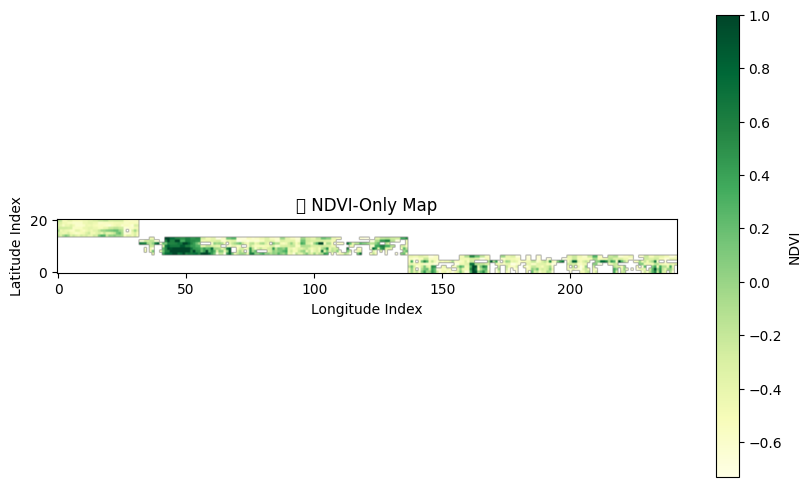

In [ ]:
# NDVI only map before ML

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load your standardized NDVI data
df = pd.read_csv("Crop_Harvest_Prediction_Model_STANDARDIZED.csv")

# Convert to numeric if needed (in case of formatting issues)
df['ndvi'] = pd.to_numeric(df['ndvi'], errors='coerce')

# Drop rows with missing or NaN NDVI
df = df.dropna(subset=['ndvi'])

# Optional: round lat/lon slightly to group nearby pixels
df['lat_index'] = df['latitude'].round(5)
df['lon_index'] = df['longitude'].round(5)

# Pivot the table to create a 2D NDVI grid
ndvi_map = df.pivot_table(values='ndvi', index='lat_index', columns='lon_index')

# Plot the NDVI-only map
plt.figure(figsize=(10, 6))
cmap = plt.cm.YlGn  # Green color scheme
plt.imshow(ndvi_map, cmap=cmap, origin='lower')
plt.colorbar(label='NDVI')
plt.title("🟢 NDVI-Only Map")
plt.xlabel("Longitude Index")
plt.ylabel("Latitude Index")
plt.show()


In [ ]:
# Decision trees model and generate validation and test report

import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# 1. Load the standardized dataset
df = pd.read_csv('Crop_Harvest_Prediction_Model_STANDARDIZED.csv')

# 2. Create crop stage labels from NDVI thresholds
def label_crop_stage(ndvi):
    if ndvi > 0.6:
        return 'Harvest-ready'
    elif ndvi > 0.3:
        return 'Immature'
    else:
        return 'Delayed'

df['label'] = df['ndvi'].apply(label_crop_stage)

# 3. Use all vegetation indices as features (inputs to the model)
features = ['ndvi', 'savi', 'ndmi', 'evi', 'revi']
X = df[features]
y = df['label']

# 4. Split the data: 60% Train, 20% Validation, 20% Test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

# 5. Train the Decision Tree model
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

# 6. Validation Report
print(" Validation Set Report:")
y_val_pred = model.predict(X_val)
print(classification_report(y_val, y_val_pred))

# 7. Test Report
print("\n Test Set Report:")
y_test_pred = model.predict(X_test)
print(classification_report(y_test, y_test_pred))

 Validation Set Report:
               precision    recall  f1-score   support

      Delayed       1.00      1.00      1.00       504
Harvest-ready       1.00      1.00      1.00        93
     Immature       1.00      1.00      1.00        29

     accuracy                           1.00       626
    macro avg       1.00      1.00      1.00       626
 weighted avg       1.00      1.00      1.00       626


 Test Set Report:
               precision    recall  f1-score   support

      Delayed       1.00      1.00      1.00       505
Harvest-ready       1.00      1.00      1.00        93
     Immature       1.00      1.00      1.00        28

     accuracy                           1.00       626
    macro avg       1.00      1.00      1.00       626
 weighted avg       1.00      1.00      1.00       626



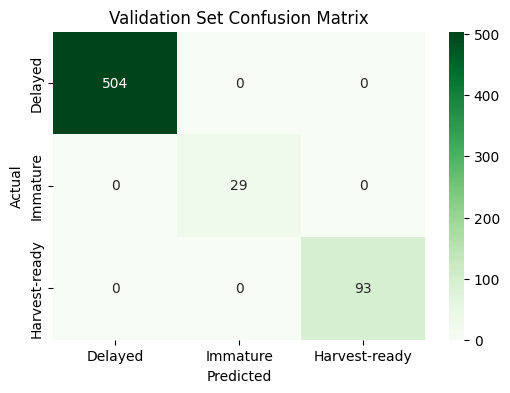

In [ ]:
# VALIDATION SET CONFUSION MATRIX

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

labels = ['Delayed', 'Immature', 'Harvest-ready']
cm_val = confusion_matrix(y_val, y_val_pred, labels=labels)

plt.figure(figsize=(6,4))
sns.heatmap(cm_val, annot=True, fmt='d', cmap='Greens',
            xticklabels=labels, yticklabels=labels)
plt.title("Validation Set Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


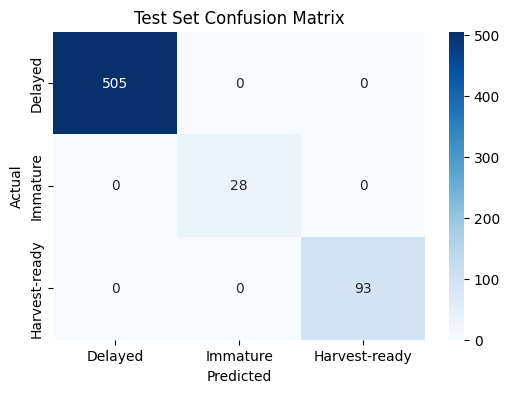

In [ ]:
# TEST SET CONFUSION MATRIX

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

labels = ['Delayed', 'Immature', 'Harvest-ready']

cm_test = confusion_matrix(y_test, y_test_pred, labels=labels)

plt.figure(figsize=(6,4))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels)
plt.title("Test Set Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


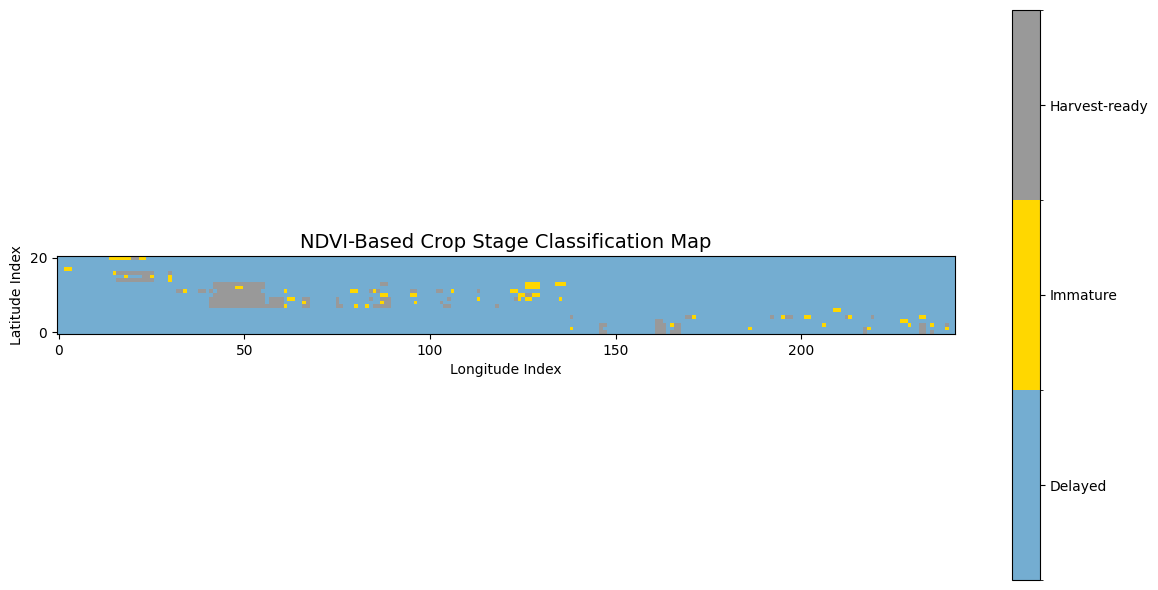

In [ ]:
# CLASSIFICATION MAP

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
import matplotlib.colors as mcolors

# 1. Load standardized dataset
df = pd.read_csv("Crop_Harvest_Prediction_Model_STANDARDIZED.csv")

# 2. NDVI to label mapping
def label_crop_stage(ndvi):
    if ndvi > 0.6:
        return 'Harvest-ready'
    elif ndvi > 0.3:
        return 'Immature'
    else:
        return 'Delayed'

df['label'] = df['ndvi'].apply(label_crop_stage)

# 3. Extract features and labels
X = df[['ndvi']]
y = df['label']
latitudes = df['latitude'].values
longitudes = df['longitude'].values

# 4. Train Decision Tree classifier
model = DecisionTreeClassifier(random_state=42)
model.fit(X, y)

# 5. Predict crop stage
df['predicted_label'] = model.predict(X)

# 6. Create grid mapping
lat_unique = np.sort(np.unique(latitudes))
lon_unique = np.sort(np.unique(longitudes))

lat_to_idx = {lat: i for i, lat in enumerate(lat_unique)}
lon_to_idx = {lon: i for i, lon in enumerate(lon_unique)}

# 7. Initialize classification grid
n_rows, n_cols = len(lat_unique), len(lon_unique)
class_map = np.full((n_rows, n_cols), -1, dtype=int)  # -1 for unmapped/missing

# Define label to int mapping (explicit ordering)
label_order = ['Delayed', 'Immature', 'Harvest-ready']
label_to_int = {label: idx for idx, label in enumerate(label_order)}

# Fill the grid
for lat, lon, label in zip(latitudes, longitudes, df['predicted_label']):
    row = lat_to_idx[lat]
    col = lon_to_idx[lon]
    class_map[row, col] = label_to_int[label]

# 8. Create custom colormap
colors = ['#74add1', '#ffd700', '#999999']  # Delayed, Immature, Harvest-ready
cmap = mcolors.ListedColormap(colors)
bounds = np.arange(len(label_order) + 1) - 0.5
norm = mcolors.BoundaryNorm(bounds, cmap.N)

# 9. Plot the classification map
plt.figure(figsize=(12, 6))
im = plt.imshow(class_map, cmap=cmap, norm=norm, origin='lower')
cbar = plt.colorbar(im, ticks=range(len(label_order)))
cbar.ax.set_yticklabels(label_order)
plt.title("NDVI-Based Crop Stage Classification Map", fontsize=14)
plt.xlabel("Longitude Index")
plt.ylabel("Latitude Index")
plt.tight_layout()
plt.show()